In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

## load diabetes data

In [16]:
df = pd.read_csv('./data/diabetes.csv')

print(df['outcome'].value_counts())

# converting outcome to binary 1 and 0
df['outcome'] = (df['outcome'] == 'success').astype(int)
df.head()

outcome
success    380
failure    319
Name: count, dtype: int64


,Unnamed: 0,treatment,outcome
0,1,met,1
1,2,rosi,0
2,3,rosi,1
3,4,lifestyle,1
4,5,met,1


In [17]:
## Crosstabs, average treatment effect:
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

df.groupby("treatment")['outcome'].mean()

outcome      0    1
treatment          
lifestyle  109  125
met        120  112
rosi        90  143 



treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: outcome, dtype: float64

Success proportion lifestyle: 0.534

Success proprtion metformin: 0.483

Success proportion rosiglitazone: 0.614

# Bootstrapping


In [18]:
## Bootstrapping:

np.random.seed(42)
R = 10_000

df_lifestyle = df.loc[ df['treatment'] == 'lifestyle',:]
df_met = df.loc[ df['treatment'] == 'met',:]
df_rosi = df.loc[ df['treatment'] == 'rosi']

outcome_met = []
outcome_rosi = []
outcome_life = [] # Store computed effects
ate_met_rosi = []
ate_met_life = []
ate_rosi_life = []


for t in range(R):
    # resampling WITHIN each arm (treatment group)
    df_met_t = df_met.sample(frac = 1.0, replace = True)
    df_rosi_t = df_rosi.sample(frac = 1.0, replace = True)
    df_life_t =  df_lifestyle.sample(frac = 1.0, replace = True)

    o_met = df_met_t['outcome'].mean()
    o_rosi = df_rosi_t['outcome'].mean()
    o_life = df_life_t['outcome'].mean()

    outcome_met.append(o_met)
    outcome_rosi.append(o_rosi)
    outcome_life.append(o_life)

    ate_met_rosi.append(o_met - o_rosi)
    ate_met_life.append(o_met - o_life)
    ate_rosi_life.append(o_rosi - o_life)

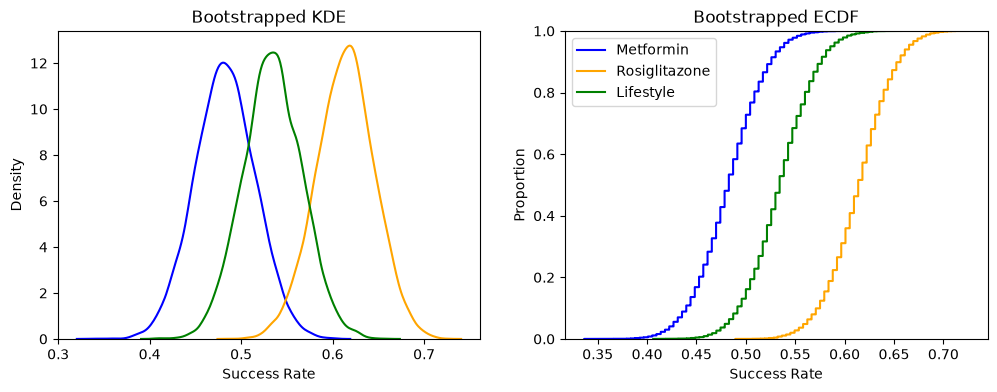

In [19]:
# plotting densities

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='Metformin', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[1])
sns.ecdfplot(outcome_life, label='Lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion') 

plt.legend()
plt.savefig("fig1_bootstrap_kde_ecdf", dpi=200, bbox_inches="tight")
plt.show()


The bootstrapped distributions show Rosiglitazone as the clear winner in terms of success rate, as its ECDF and KDE are shifted the furthest to the right with a median success rate around 0.62. Metformin appears the least successful across resamples with a median success rate around 0.47.

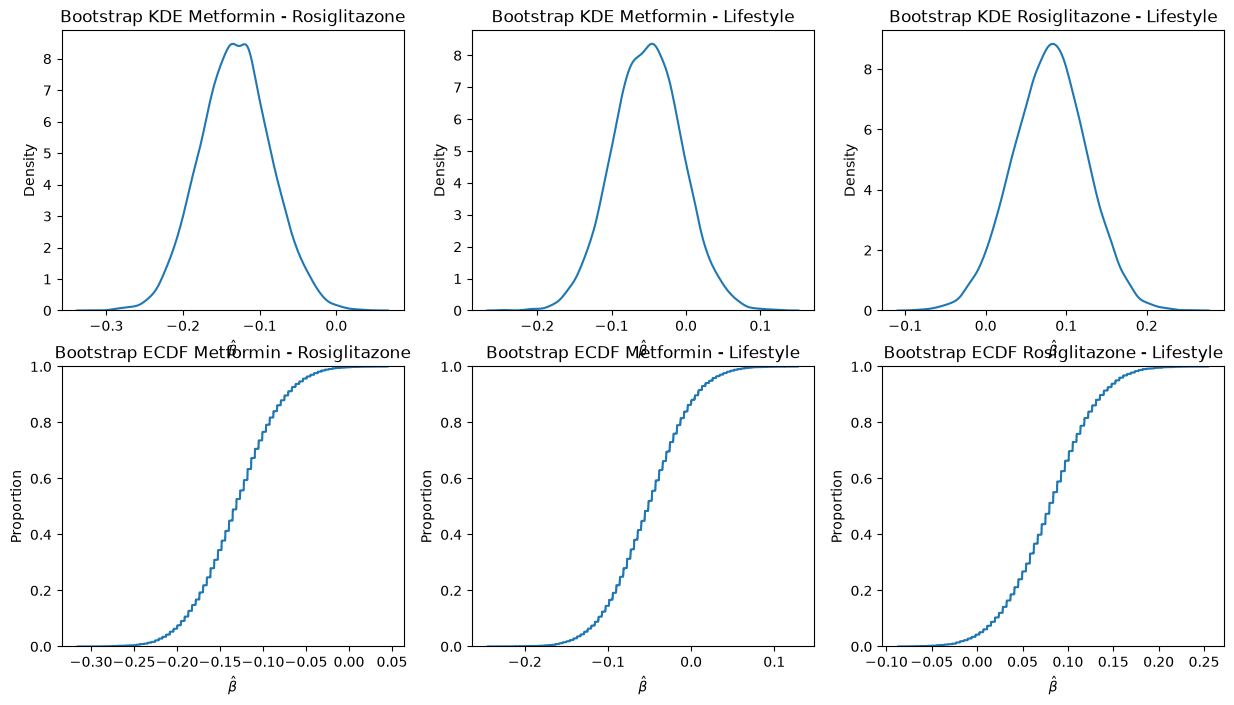

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

## KDE
sns.kdeplot(ate_met_rosi, ax=ax[0, 0])
ax[0, 0].set_xlabel(r"$\hat{\beta}$")
ax[0, 0].set_title("Bootstrap KDE Metformin - Rosiglitazone")

sns.kdeplot(ate_met_life, ax=ax[0, 1])
ax[0, 1].set_xlabel(r"$\hat{\beta}$")
ax[0, 1].set_title("Bootstrap KDE Metformin - Lifestyle")

sns.kdeplot(ate_rosi_life, ax=ax[0, 2])
ax[0, 2].set_xlabel(r"$\hat{\beta}$")
ax[0, 2].set_title("Bootstrap KDE Rosiglitazone - Lifestyle")

## ECDF
sns.ecdfplot(ate_met_rosi, ax=ax[1, 0])
ax[1, 0].set_xlabel(r"$\hat{\beta}$")
ax[1, 0].set_title("Bootstrap ECDF Metformin - Rosiglitazone")

sns.ecdfplot(ate_met_life, ax=ax[1, 1])
ax[1, 1].set_xlabel(r"$\hat{\beta}$")
ax[1, 1].set_title("Bootstrap ECDF Metformin - Lifestyle")

sns.ecdfplot(ate_rosi_life, ax=ax[1, 2])
ax[1, 2].set_xlabel(r"$\hat{\beta}$")
ax[1, 2].set_title("Bootstrap ECDF Rosiglitazone - Lifestyle")
plt.savefig("fig2_bootstrap_treatment_effects", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
ci90_met_ros = np.quantile(ate_met_rosi, [0.05, 0.95])
ci95_met_ros = np.quantile(ate_met_rosi, [0.025, 0.975])
ci99_met_ros = np.quantile(ate_met_rosi, [0.005, 0.995])

ci90_met_life = np.quantile(ate_met_life, [0.05, 0.95])
ci95_met_life = np.quantile(ate_met_life, [0.025, 0.975])
ci99_met_life = np.quantile(ate_met_life, [0.005, 0.995])

ci90_rosi_life = np.quantile(ate_rosi_life, [0.05, 0.95])
ci95_rosi_life = np.quantile(ate_rosi_life, [0.025, 0.975])
ci99_rosi_life = np.quantile(ate_rosi_life, [0.005, 0.995])

In [22]:
print(f"90% CI Met - Ros: {ci90_met_ros}")
print(f"95% CI Met - Ros: {ci95_met_ros}")
print(f"99% CI Met - Ros: {ci99_met_ros}")

print(f"90% CI Met - Life: {ci90_met_life}")
print(f"95% CI Met - Life: {ci95_met_life}")
print(f"99% CI Met - Life: {ci99_met_life}")

print(f"90% CI Rosi - Life: {ci90_rosi_life}")
print(f"95% CI Rosi - Life: {ci95_rosi_life}")
print(f"99% CI Rosi - Life: {ci99_rosi_life}")

90% CI Met - Ros: [-0.20832193 -0.05361107]
95% CI Met - Ros: [-0.221271   -0.04055054]
99% CI Met - Ros: [-0.24724369 -0.01061862]
90% CI Met - Life: [-0.12857353  0.02556734]
95% CI Met - Life: [-0.14161601  0.0387931 ]
99% CI Met - Life: [-0.17130931  0.06867098]
90% CI Rosi - Life: [0.00256777 0.15250724]
95% CI Rosi - Life: [-0.01041827  0.16939951]
99% CI Rosi - Life: [-0.04027787  0.19529786]


Met - Ros: every interval is entirely negative even at 99%. metformin's success rate is lower than rosiglitazone's. 95% CI says gap somewhere between 4 and 22%.

Met - lifestlye: every interval spans 0. no evidence that these two differ. small advantage for either treatment is plausible

rosi vs lifestyle: 90% interval just barely excludes 0 but 95% and 99% intervals include it. barely evidence. lower bound VERY close to 0 on 90% interval, so minimal evidence that rosiglitazone is more effective than lifestyle. 

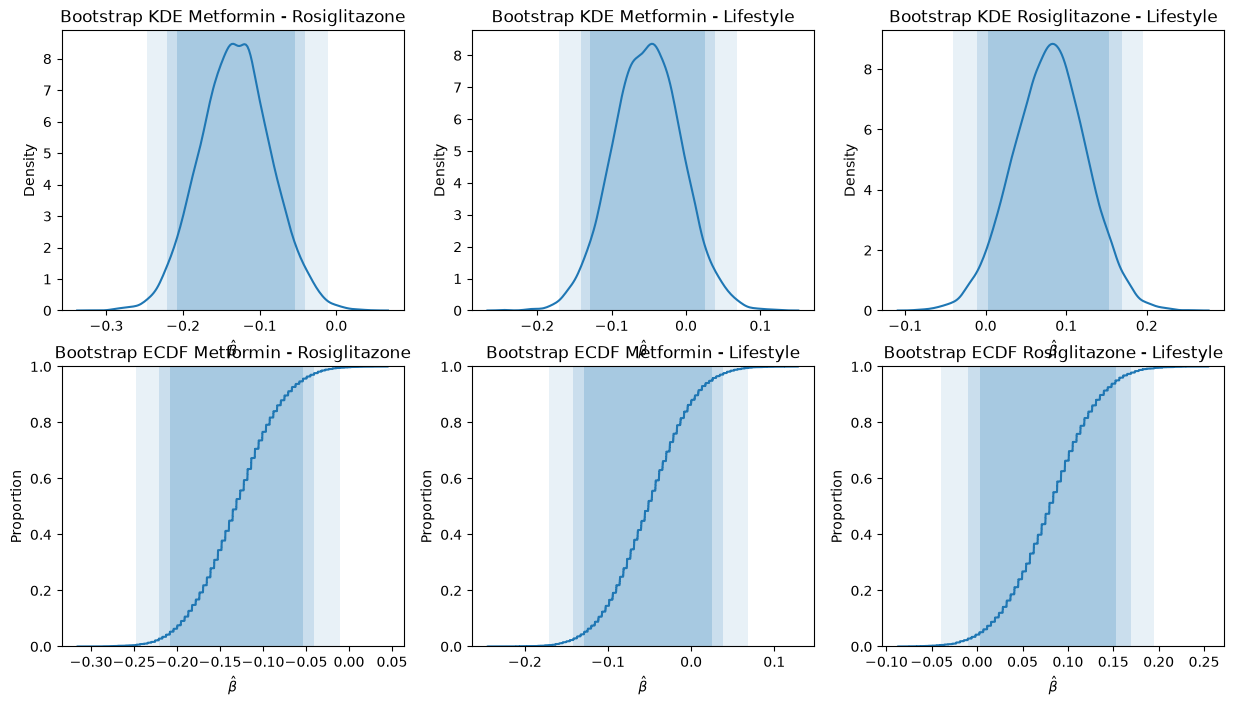

In [23]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

## KDE
sns.kdeplot(ate_met_rosi, ax=ax[0, 0])
ax[0, 0].set_xlabel(r"$\hat{\beta}$")
ax[0, 0].set_title("Bootstrap KDE Metformin - Rosiglitazone")
ax[0, 0].axvspan(ci99_met_ros[0], ci99_met_ros[1], alpha=0.10, label="99% CI")
ax[0, 0].axvspan(ci95_met_ros[0], ci95_met_ros[1], alpha=0.15, label="95% CI")
ax[0, 0].axvspan(ci90_met_ros[0], ci90_met_ros[1], alpha=0.20, label="90% CI")

sns.kdeplot(ate_met_life, ax=ax[0, 1])
ax[0, 1].set_xlabel(r"$\hat{\beta}$")
ax[0, 1].set_title("Bootstrap KDE Metformin - Lifestyle")
ax[0, 1].axvspan(ci99_met_life[0], ci99_met_life[1], alpha=0.10, label="99% CI")
ax[0, 1].axvspan(ci95_met_life[0], ci95_met_life[1], alpha=0.15, label="95% CI")
ax[0, 1].axvspan(ci90_met_life[0], ci90_met_life[1], alpha=0.20, label="90% CI")



sns.kdeplot(ate_rosi_life, ax=ax[0, 2])
ax[0, 2].set_xlabel(r"$\hat{\beta}$")
ax[0, 2].set_title("Bootstrap KDE Rosiglitazone - Lifestyle")
ax[0, 2].axvspan(ci99_rosi_life[0], ci99_rosi_life[1], alpha=0.10, label="99% CI")
ax[0, 2].axvspan(ci95_rosi_life[0], ci95_rosi_life[1], alpha=0.15, label="95% CI")
ax[0, 2].axvspan(ci90_rosi_life[0], ci90_rosi_life[1], alpha=0.20, label="90% CI")



## ECDF
sns.ecdfplot(ate_met_rosi, ax=ax[1, 0])
ax[1, 0].set_xlabel(r"$\hat{\beta}$")
ax[1, 0].set_title("Bootstrap ECDF Metformin - Rosiglitazone")
ax[1, 0].axvspan(ci99_met_ros[0], ci99_met_ros[1], alpha=0.10, label="99% CI")
ax[1, 0].axvspan(ci95_met_ros[0], ci95_met_ros[1], alpha=0.15, label="95% CI")
ax[1, 0].axvspan(ci90_met_ros[0], ci90_met_ros[1], alpha=0.20, label="90% CI")


sns.ecdfplot(ate_met_life, ax=ax[1, 1])
ax[1, 1].set_xlabel(r"$\hat{\beta}$")
ax[1, 1].set_title("Bootstrap ECDF Metformin - Lifestyle")
ax[1, 1].axvspan(ci99_met_life[0], ci99_met_life[1], alpha=0.10, label="99% CI")
ax[1, 1].axvspan(ci95_met_life[0], ci95_met_life[1], alpha=0.15, label="95% CI")
ax[1, 1].axvspan(ci90_met_life[0], ci90_met_life[1], alpha=0.20, label="90% CI")

sns.ecdfplot(ate_rosi_life, ax=ax[1, 2])
ax[1, 2].set_xlabel(r"$\hat{\beta}$")
ax[1, 2].set_title("Bootstrap ECDF Rosiglitazone - Lifestyle")
ax[1, 2].axvspan(ci99_rosi_life[0], ci99_rosi_life[1], alpha=0.10, label="99% CI")
ax[1, 2].axvspan(ci95_rosi_life[0], ci95_rosi_life[1], alpha=0.15, label="95% CI")
ax[1, 2].axvspan(ci90_rosi_life[0], ci90_rosi_life[1], alpha=0.20, label="90% CI")

plt.savefig("fig3_bootstrap_treatment_effects_ci", dpi=200, bbox_inches="tight")
plt.show()